# Extended data exploration
The previous data exploration showed the temperature over time.<br>
I would like to expand this by looking at the seasonal trends instead of the temporal trends.<br>
This is because the country data is per month, and combining all data from over the world will mix the seasons. 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

In [3]:
df_city = pd.read_parquet("ClimateData_clean/city_data.parquet")
df_city["year"] = df_city.dt.dt.year
df_city["month"] = df_city.dt.dt.month

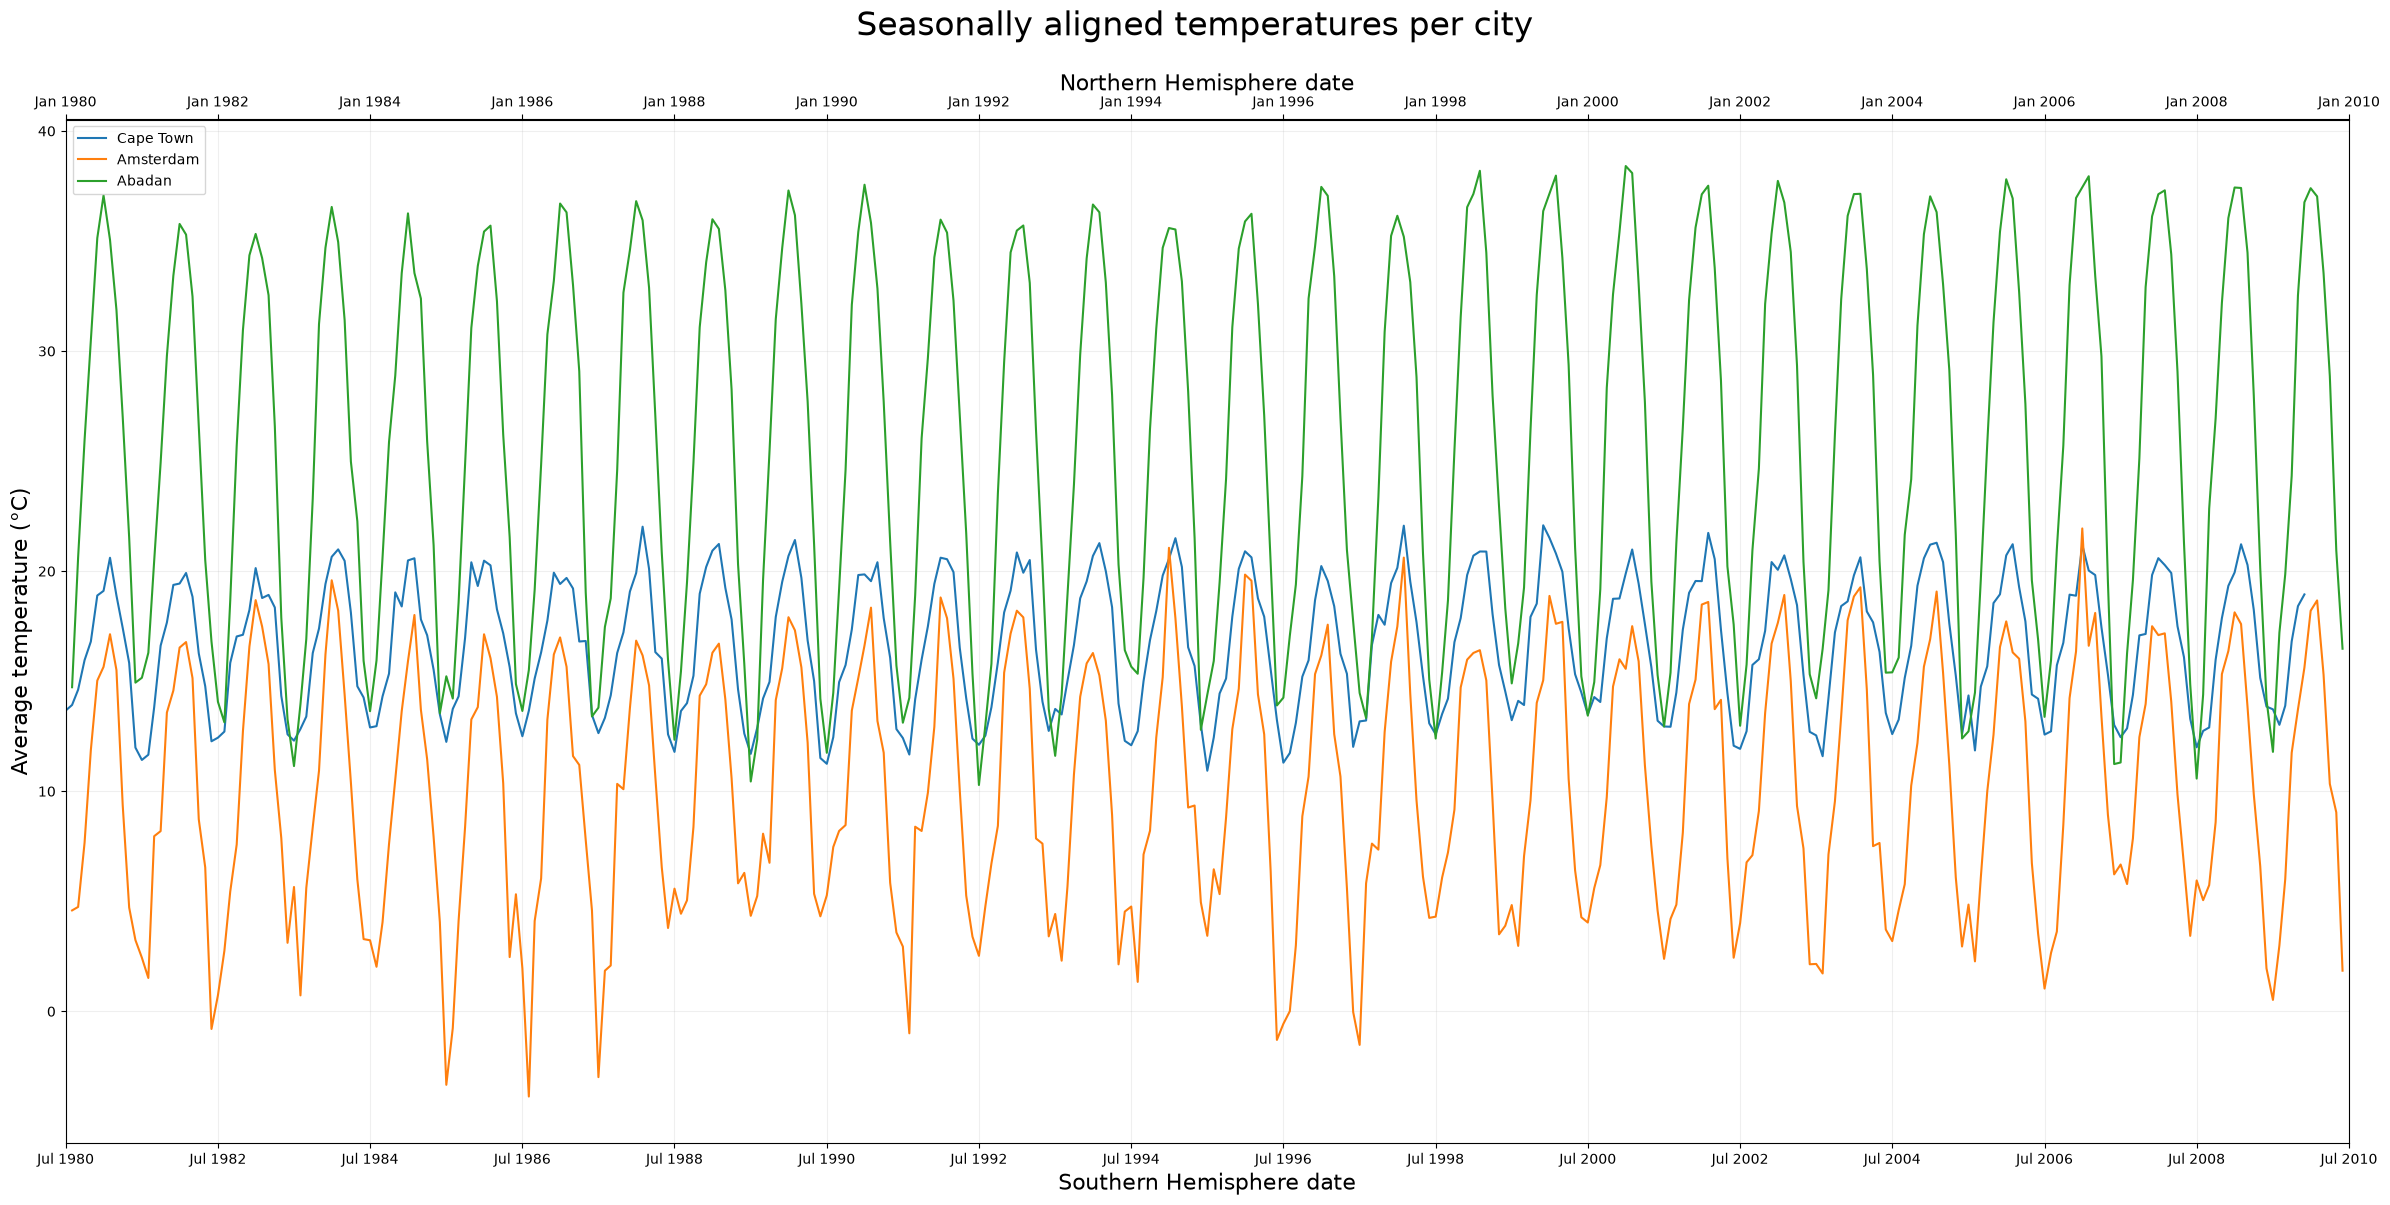

In [7]:
northern_hemisphere_cond = df_city["Latitude"].str.endswith("N")
df_city["dt_shifted"] = np.where(
    northern_hemisphere_cond, 
    df_city["dt"],                             
    df_city["dt"] - pd.DateOffset(months=6)                        
    )

min_date = "1980-01-01"
max_date = "2010-01-01"

df_city_filter_date = df_city[
    (df_city["dt"] > min_date)
    & (df_city["dt"] < max_date)
]

df_city_sorted = df_city_filter_date.sort_values(["City", "Country", "dt_shifted"])

cities = [
    "Cape Town", 
    "Amsterdam",
    # "Stockholm",
    # "Madrid",
    # "Sydney",
    "Abadan"
    ]

# Temperature per city/global
fig, ax = plt.subplots(figsize=(24, 12))
for city in cities:
    city_data = df_city_sorted[
        df_city_sorted["City"] == city
    ]

    ax.plot(
        city_data["dt_shifted"],
        city_data["AverageTemperatureCleaned"],
        label=city
    )

# Southern Hemisphere date formatter
def southern_date_formatter(x, pos):
    date = pd.Timestamp(mdates.num2date(x))
    original_date = date + pd.DateOffset(months=6)

    return original_date.strftime("%b %Y")

# Primary x-axis (Southern Hemisphere)
ax.set_xlim(pd.Timestamp(min_date), pd.Timestamp(max_date))
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(
    FuncFormatter(southern_date_formatter)
)
ax.set_xlabel("Southern Hemisphere date", fontsize=16)

# Secondary x-axis (Northern Hemisphere)
ax2 = ax.secondary_xaxis("top")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax2.set_xlabel("Northern Hemisphere date", fontsize=16)


# Plot formatting
ax.set_ylabel("Average temperature (°C)", fontsize=16)
ax.legend()
ax.grid(alpha=0.2)

fig.suptitle("Seasonally aligned temperatures per city", fontsize=24, y=1)

plt.tight_layout()
plt.show()